# Título Interesante y Llamativo del Proyecto
## Definición del problema
abc ns ustedes mismos son
## Variables a analizar
### Precipitación:
Los datos recogidos provienen de las siguientes fuentes:
- PISCO: una descripción breve tal vez | Formato: .csv | Forma de acceso: https://figshare.com/articles/dataset/High-resolution_grids_of_rainfall_for_Peru_-_PISCOp_v3_0_dataset/32411886
- climateSERV: acá tmb | Formato: .nc | Forma de acceso
### Cobertura de suelo:
Los datos recogidos provienen de las siguientes fuentes:
- Mapbiomas: acá tmb | Formato: ns | Forma de acceso: ns
- MODIS/061/MCD12Q1: acá tmb | Formato: ns | Forma de acceso: ns
### Enlaces adicionales
- Drive: https://drive.google.com/drive/folders/1gPHBk7qCmcYYvy80GQ7GV8aXXrpXl6pX?usp=sharing
- GitHub: https://github.com/SALINASSebas/geocomp_TF.git

In [ ]:
# Paso 0: Importación de librerías
import os
import shutil
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr
import ee
import requests
import rioxarray as rio
from rasterio.enums import Resampling

os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["GDAL_HTTP_MERGE_CONSECUTIVE_RANGES"] = "YES"
os.environ["VSI_CACHE"] = "TRUE"

# Exploración preliminar de datos
## Precipitación
### 1. PISCO

In [43]:
# Se llaman los archivos desde la carpeta de Google Drive:
# !pip install gdown -q
import gdown

gdown.download_folder(id='1gPHBk7qCmcYYvy80GQ7GV8aXXrpXl6pX', output='datos_brutos', quiet=False, use_cookies=True)

Retrieving folder contents


Retrieving folder 1mFD0cbvhUxPbqgBpCjBqvouSHBv_LzOT datos_climateSERV
Processing file 1o7Eaw8l0DkdqzfZAwIC8hPyiCFSEA96y README.txt
Processing file 16_D0NsW-YV3hCD3p3_Xxb3yWiQIzKPwv SERV_CHIRPS_1.nc
Processing file 1KmkRM1HjpKMml4zn5b8MtP9KLIn3F_Aa SERV_CHIRPS_2.nc
Processing file 13aHPxEO3p0OugSfzVrB1b2gscysnNExM SERV_CHIRPS_3.nc
Processing file 1PSILew8WN0x0xfomPF-E2ErxsqnNsiai SERV_CHIRPS_4.nc
Retrieving folder 19sYIVFEKuJ4bQMPyodgMRlKW3RVFReuw datos_PISCO
Processing file 1wj-ymOGDYzQfYmoNHZ8Hmb81RN3PaxVL PISCOp_m.nc
Processing file 1n-KhItYZTEa1XbZqp-xTwHe0sFaB35TB README.txt
Retrieving folder 1oL_1bbvLptq-lKKH1SxiXdmkKgFQIHrZ SHAPEFILES
Processing file 1e0lrb5p6d8fYhCY4e8YR7jdhGgJFskbj bofAntauta.gpkg
Processing file 1-OJUBDYp6VOwOTApYpBz9tjjGBFziXbd bofCaplina.gpkg
Processing file 1gSo_wx6wtJjFDL7BWqT9_H2Xu-vG3xXl SHAPEFILES_bof-20261015T211729Z-1-001.zip
Processing file 1pIQT-bNbn8PFl8yp3KyyUVQ6JDh5yJyC UniHidroMen_ANA_geogpsperu.zip


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1o7Eaw8l0DkdqzfZAwIC8hPyiCFSEA96y
To: /home/sebas/GitHub/geocomp_TF/datos_brutos/datos_climateSERV/README.txt
100%|██████████| 308/308 [00:00<00:00, 190kB/s]
Downloading...
From: https://drive.google.com/uc?id=16_D0NsW-YV3hCD3p3_Xxb3yWiQIzKPwv
To: /home/sebas/GitHub/geocomp_TF/datos_brutos/datos_climateSERV/SERV_CHIRPS_1.nc
100%|██████████| 251k/251k [00:00<00:00, 1.49MB/s]
Downloading...
From: https://drive.google.com/uc?id=1KmkRM1HjpKMml4zn5b8MtP9KLIn3F_Aa
To: /home/sebas/GitHub/geocomp_TF/datos_brutos/datos_climateSERV/SERV_CHIRPS_2.nc
100%|██████████| 211k/211k [00:00<00:00, 1.32MB/s]
Downloading...
From: https://drive.google.com/uc?id=13aHPxEO3p0OugSfzVrB1b2gscysnNExM
To: /home/sebas/GitHub/geocomp_TF/datos_brutos/datos_climateSERV/SERV_CHIRPS_3.nc
100%|██████████| 211k/211k [00:00<00:00, 1.42MB/s]
Downloading...
From: https:/

['datos_brutos/datos_climateSERV/README.txt',
 'datos_brutos/datos_climateSERV/SERV_CHIRPS_1.nc',
 'datos_brutos/datos_climateSERV/SERV_CHIRPS_2.nc',
 'datos_brutos/datos_climateSERV/SERV_CHIRPS_3.nc',
 'datos_brutos/datos_climateSERV/SERV_CHIRPS_4.nc',
 'datos_brutos/datos_PISCO/PISCOp_m.nc',
 'datos_brutos/datos_PISCO/README.txt',
 'datos_brutos/SHAPEFILES/bofAntauta.gpkg',
 'datos_brutos/SHAPEFILES/bofCaplina.gpkg',
 'datos_brutos/SHAPEFILES/SHAPEFILES_bof-20261015T211729Z-1-001.zip',
 'datos_brutos/SHAPEFILES/UniHidroMen_ANA_geogpsperu.zip']

In [65]:
ruta = '/home/sebas/GitHub/geocomp_TF/datos_brutos/'
archivo = 'datos_PISCO/PISCOp_m.nc'

pisco = xr.open_dataset(ruta+archivo)
pisco

<xarray.Dataset> Size: 79MB
Dimensions:        (Z1: 540, latitude: 210, longitude: 174)
Coordinates:
  * Z1             (Z1) int32 2kB 1 2 3 4 5 6 7 ... 534 535 536 537 538 539 540
  * latitude       (latitude) float64 2kB 1.95 1.85 1.75 ... -18.85 -18.95
  * longitude      (longitude) float64 1kB -81.35 -81.25 ... -64.15 -64.05
Data variables:
    precipitation  (Z1, latitude, longitude) float32 79MB ...
    crs            int32 4B ...
Attributes:
    Conventions:   CF-1.4
    created_by:    R packages ncdf4 and terra (version 1.8-70)
    created_date:  2026-05-26 18:28:02

In [3]:
# La data recopila datos mensuales promedio de precipitación en un rango de 1981-2025. Se debe seleccionar los meses correspondientes a los años de interés:
ini = '1981-1-1'
fin = '2025-12-1'
fecha = pd.date_range(ini,fin, freq='MS')#.to_period('M')

# Se asigna las nuevas coordenadas y se renombra la dimensión Z1
rname = {'Z1':'time'}
pisco_date = pisco.assign_coords(Z1=fecha).rename(rname)

# Se selecciona los meses correspondientes al rango de fechas de interés para la variable de precipitación
pisco_p = pisco_date['precipitation'].sel(time=slice('2000-1-1','2024-12-1'))
pisco_p

<xarray.DataArray 'precipitation' (time: 300, latitude: 210, longitude: 174)> Size: 44MB
[10962000 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[us] 2kB 2000-01-01 2000-02-01 ... 2024-12-01
  * latitude   (latitude) float64 2kB 1.95 1.85 1.75 ... -18.75 -18.85 -18.95
  * longitude  (longitude) float64 1kB -81.35 -81.25 -81.15 ... -64.15 -64.05
Attributes:
    units:         mm
    long_name:     PISCOp_v3.0: Gridded rainfall dataset for Peru from 1981 t...
    grid_mapping:  crs

In [4]:
# Se definen los límites espaciales de interés en base a la información geográfica de los bofedales
# Primero, se carga la data de los geopackages respectivos
ruta1 = '/home/sebas/GitHub/geocomp_TF/datos_brutos/SHAPEFILES/'

bof_antauta = gpd.read_file(ruta1+'bofAntauta.gpkg')
bof_caplina = gpd.read_file(ruta1+'bofCaplina.gpkg')

In [ ]:
# Se selecciona la data mínima y máxima de las latitudes y longitudes de los bofedales
def georecorte(xarr: xr.DataArray, geodf: gpd.GeoDataFrame, buffer: float=0, rev=False, box=False) -> xr.DataArray:
    """Devuelve el DataArray recortado en la extensión espacial de la data georreferenciada y la extensión del recorte
    xarr: DataArray | 
    geodf: GeoDataFrame base para hacer el recorte | 
    buffer: Extensión agregada al recorte | 
    rev: Define si el recorte de latitud se da de min a max (False) o viceversa (True) | 
    box: Define si devuelve la lista de límites"""
    min_x = float(geodf.total_bounds[0])-buffer
    min_y = float(geodf.total_bounds[1])-buffer
    max_x = float(geodf.total_bounds[2])+buffer
    max_y = float(geodf.total_bounds[3])+buffer

    if box:
        if rev:
            return [min_x, min_y, max_x, max_y], xarr.sel(latitude=slice(max_y,min_y), longitude=slice(min_x,max_x))
        else:
            return [min_x, min_y, max_x, max_y], xarr.sel(latitude=slice(min_y,max_y), longitude=slice(min_x,max_x))
    else:
        if rev:
            return xarr.sel(latitude=slice(max_y,min_y), longitude=slice(min_x,max_x))
        else:
            return xarr.sel(latitude=slice(min_y,max_y), longitude=slice(min_x,max_x))

box_antauta, p_ant_pisco = georecorte(pisco_p, bof_antauta, .2, rev=True, box=True)
box_caplina, p_cap_pisco = georecorte(pisco_p, bof_caplina, .2, rev=True, box=True)

In [95]:
# Visualización de datos recortados
p_ant_pisco

<xarray.DataArray 'precipitation' (time: 300, latitude: 5, longitude: 5)> Size: 30kB
[7500 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[us] 2kB 2000-01-01 2000-02-01 ... 2024-12-01
  * latitude   (latitude) float64 40B -14.05 -14.15 -14.25 -14.35 -14.45
  * longitude  (longitude) float64 40B -70.55 -70.45 -70.35 -70.25 -70.15
Attributes:
    units:         mm
    long_name:     PISCOp_v3.0: Gridded rainfall dataset for Peru from 1981 t...
    grid_mapping:  crs

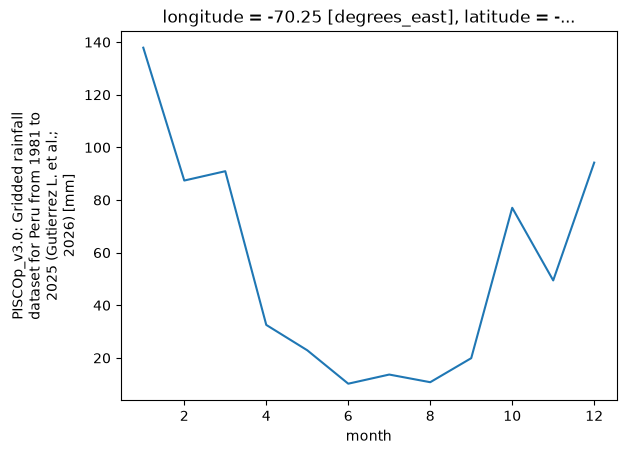

In [ ]:
# Visualización de precipitación promedio mensual para una coordenada específica en Antauta
punto = p_ant_pisco.sel(latitude=-14.3, longitude=-70.3, method='nearest')

punto.groupby('time.month').mean(dim='time').plot(x='month')

<Axes: title={'center': 'month = 5'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

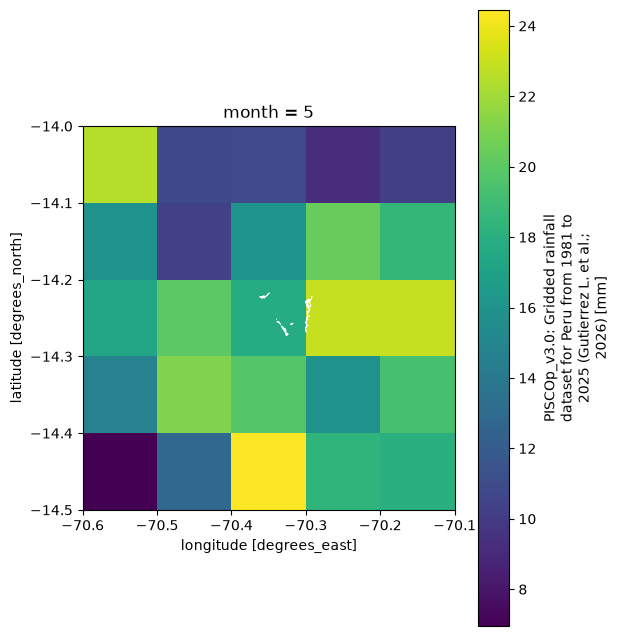

In [ ]:
# Visualización de la precipitación promedio del área de los bofedales de Antauta en junio 
fig, ax = plt.subplots(figsize=(6,8))
p_ant_pisco.groupby('time.month').mean().sel(month=5).plot()
bof_antauta.plot(ax=ax, facecolor='none', edgecolor='white', linewidth=0.5)

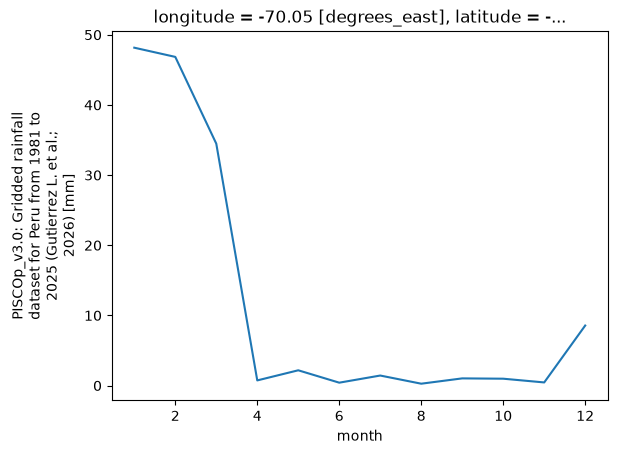

In [ ]:
# Visualización de precipitación promedio mensual para una coordenada específica en Caplina
punto = p_cap_pisco.sel(latitude=-14.3, longitude=-70.3, method='nearest')

punto.groupby('time.month').mean(dim='time').plot(x='month')

<Axes: title={'center': 'month = 5'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

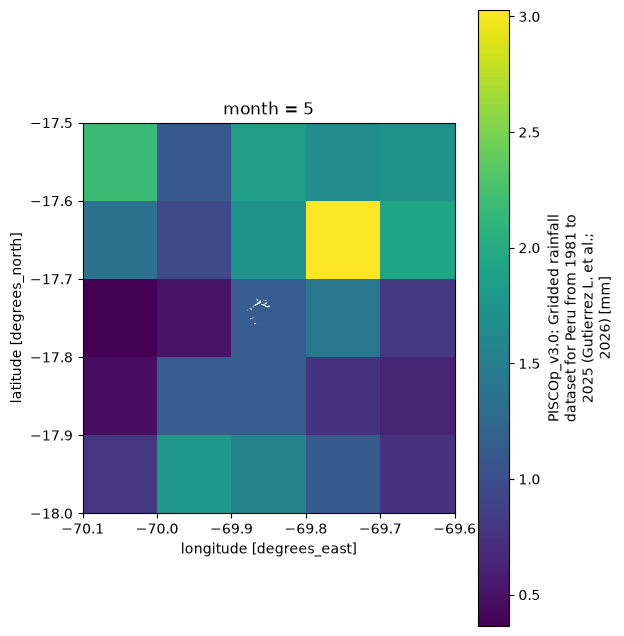

In [108]:
# Visualización de la precipitación promedio del área de los bofedales de Caplina en junio 
fig, ax = plt.subplots(figsize=(6,8))
p_cap_pisco.groupby('time.month').mean().sel(month=5).plot()
bof_caplina.plot(ax=ax, facecolor='none', edgecolor='white', linewidth=0.5)

### 2. climateSERV

In [ ]:
# Se define la nueva ruta de archivos
ruta2 = ruta + 'datos_climateSERV/'
archivos = {
    "SERV_1":   ruta2 + "SERV_CHIRPS_1.nc",
    "SERV_2":   ruta2 + "SERV_CHIRPS_2.nc",
    "SERV_3":   ruta2 + "SERV_CHIRPS_3.nc",
    "SERV_4":   ruta2 + "SERV_CHIRPS_4.nc",
    "SERV_5":   ruta2 + "SERV_CHIRPS_5.nc"
}

In [109]:
# Por medio de una lista se añade la data de cada dataset y se concatena por la dimensión 'time'
partes = []
for escenario, ruta2 in archivos.items(): # Items() devuelve la lista con los keys y valores del diccionario
    df = xr.open_dataset(ruta2) # Dado que ruta2 es un solo valor, se pide que se cree un dataframe a partir del dato de ruta
    partes.append(df)

serv = xr.concat(partes, dim='time')
serv

<xarray.Dataset> Size: 129MB
Dimensions:               (time: 9132, latitude: 101, longitude: 35)
Coordinates:
  * time                  (time) datetime64[ns] 73kB 2000-01-01 ... 2024-12-31
  * latitude              (latitude) float64 808B -18.48 -18.43 ... -13.48
  * longitude             (longitude) float64 280B -71.02 -70.97 ... -69.32
Data variables:
    precipitation_amount  (time, latitude, longitude) float32 129MB nan ... nan

In [ ]:
# Se define 'precipitation_amount' como única variable del nuevo dataArray
serv_p = datos['precipitation_amount']
serv_p

<xarray.DataArray 'precipitation_amount' (time: 9132, latitude: 101,
                                          longitude: 35)> Size: 129MB
array([[[       nan,        nan,        nan, ...,  4.020291 ,
          3.9108918,  3.8817017],
        [       nan,        nan,        nan, ...,  3.7455232,
          3.8515646,  3.8292072],
        [       nan,        nan,        nan, ...,  0.       ,
          3.9118545,  3.85269  ],
        ...,
        [       nan, 15.004898 , 12.905757 , ..., 12.646875 ,
         12.534734 , 12.537279 ],
        [       nan, 15.733972 , 13.396576 , ..., 13.066465 ,
         12.510356 , 12.565484 ],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[       nan,        nan,        nan, ...,  0.       ,
          0.       ,  0.       ],
        [       nan,        nan,        nan, ...,  0.       ,
          0.       ,  0.       ],
        [       nan,        nan,        nan, ...,  0.       ,
          0.       ,  0.       ],
...
        [       nan,  1.9131895,  2.8221152, ...,  0.       ,
          0.       ,  0.       ],
        [       nan,  2.047651 ,  1.6169802, ...,  0.       ,
          0.       ,  0.       ],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]],

       [[       nan,        nan,        nan, ...,  0.       ,
          0.       ,  0.       ],
        [       nan,        nan,        nan, ...,  0.       ,
          0.       ,  0.       ],
        [       nan,        nan,        nan, ...,  0.       ,
          0.       ,  0.       ],
        ...,
        [       nan,  0.       ,  0.       , ...,  0.       ,
          0.       ,  0.       ],
        [       nan,  2.047651 ,  1.6169802, ...,  0.       ,
          0.       ,  0.       ],
        [       nan,        nan,        nan, ...,        nan,
                nan,        nan]]], shape=(9132, 101, 35), dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 73kB 2000-01-01 2000-01-02 ... 2024-12-31
  * latitude   (latitude) float64 808B -18.48 -18.43 -18.38 ... -13.53 -13.48
  * longitude  (longitude) float64 280B -71.02 -70.97 -70.92 ... -69.37 -69.32
Attributes:
    long_name:              precipitation_amount
    units:                  mm
    accumulation_interval:  1 day
    comment:                Climate Hazards group InfraRed Precipitation with...
    cell_methods:           time: mean

In [ ]:
# Se realiza el recorte espacial de la data
p_ant_serv = georecorte(serv_p, bof_antauta, .3)
p_cap_serv = georecorte(serv_p, bof_caplina, .3)

In [ ]:
# Visualización de la data procesada
p_ant_serv

<xarray.DataArray 'precipitation_amount' (time: 9132, latitude: 13,
                                          longitude: 13)> Size: 6MB
array([[[11.062643 ,  9.400809 ,  9.739962 , ..., 11.528743 ,
         14.157229 , 14.263801 ],
        [ 9.8882265,  8.419459 ,  8.662639 , ..., 10.971813 ,
         13.848125 , 14.120755 ],
        [ 9.647578 , 10.067948 , 10.300497 , ..., 10.380214 ,
          7.347652 ,  7.4634476],
        ...,
        [10.057936 , 10.401931 , 10.608632 , ...,  6.3149943,
          6.565145 ,  6.8996115],
        [ 8.5231285, 11.163639 , 11.502245 , ...,  6.171667 ,
          6.5190244,  7.021554 ],
        [ 8.497939 , 11.162478 , 11.55842  , ...,  6.111651 ,
          6.438233 ,  6.9284854]],

       [[ 0.       ,  0.       ,  0.       , ...,  0.       ,
          0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       , ...,  0.       ,
          0.       ,  0.       ],
        [ 0.       ,  2.516987 ,  2.5751243, ...,  0.       ,
          0.       ,  0.       ],
...
        [ 0.       ,  0.       ,  0.       , ...,  0.       ,
          0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       , ...,  0.       ,
          0.       ,  0.       ],
        [ 0.       ,  0.       ,  0.       , ...,  0.       ,
          0.       ,  0.       ]],

       [[ 2.3310719,  3.1891274,  6.88268  , ...,  0.       ,
          0.       ,  0.       ],
        [ 1.7576896,  3.946874 ,  5.1177287, ...,  0.       ,
          2.003426 ,  0.       ],
        [ 0.       ,  2.518643 ,  3.3973942, ...,  0.       ,
          0.       ,  0.       ],
        ...,
        [ 3.0351634,  0.       ,  0.       , ...,  0.       ,
          0.       ,  0.       ],
        [ 2.3115919,  0.       ,  1.3807119, ...,  0.       ,
          0.       ,  0.       ],
        [ 4.2091956,  3.87138  ,  5.118828 , ...,  0.       ,
          0.       ,  0.       ]]], shape=(9132, 13, 13), dtype=float32)
Coordinates:
  * time       (time) datetime64[ns] 73kB 2000-01-01 2000-01-02 ... 2024-12-31
  * latitude   (latitude) float64 104B -14.53 -14.48 -14.43 ... -13.98 -13.93
  * longitude  (longitude) float64 104B -70.62 -70.57 -70.52 ... -70.07 -70.02
Attributes:
    long_name:              precipitation_amount
    units:                  mm
    accumulation_interval:  1 day
    comment:                Climate Hazards group InfraRed Precipitation with...
    cell_methods:           time: mean

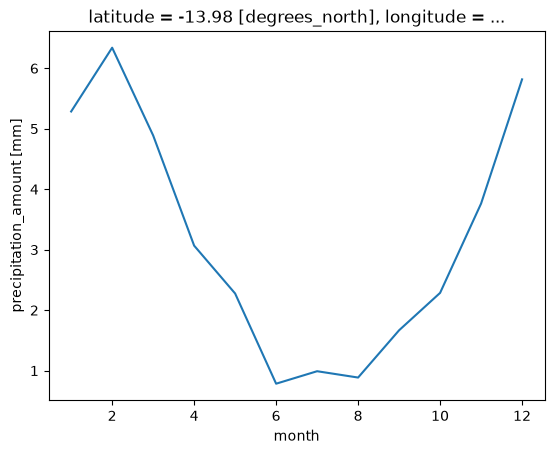

In [ ]:
# Visualización de precipitación promedio anual para una coordenada específica en Antauta
punto_ant = p_ant_serv.sel(latitude=-14, longitude=-70, method='nearest')

punto_ant.groupby('time.month').mean(dim='time').plot()

<Axes: title={'center': 'month = 5'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

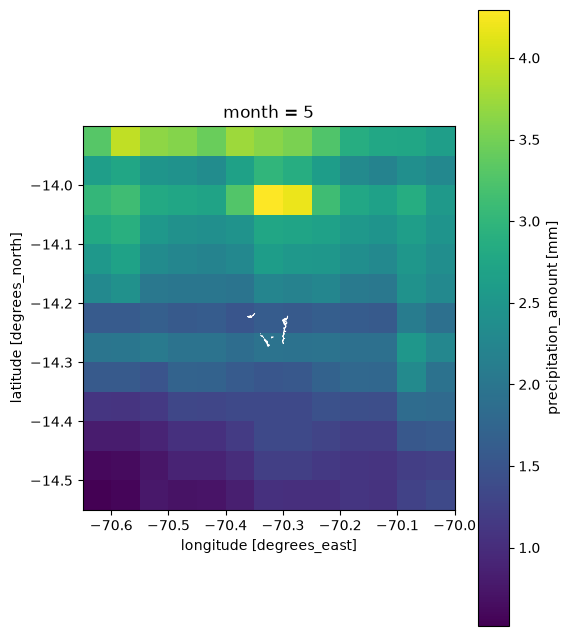

In [ ]:
# Visualización de la precipitación promedio del área de los bofedales de Antauta en junio 
fig, ax = plt.subplots(figsize=(6,8))
p_ant_serv.groupby('time.month').mean().sel(month=5).plot()
bof_antauta.plot(ax=ax, facecolor='none', edgecolor='white', linewidth=0.5)

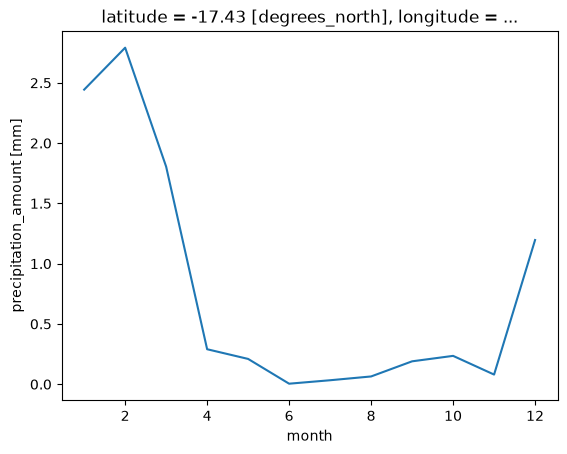

In [ ]:
# Visualización de precipitación promedio mensual para una coordenada específica en Caplina
punto_cap = p_cap_serv.sel(latitude=-14, longitude=-70, method='nearest')

punto_cap.groupby('time.month').mean(dim='time').plot()

<Axes: title={'center': 'month = 5'}, xlabel='longitude [degrees_east]', ylabel='latitude [degrees_north]'>

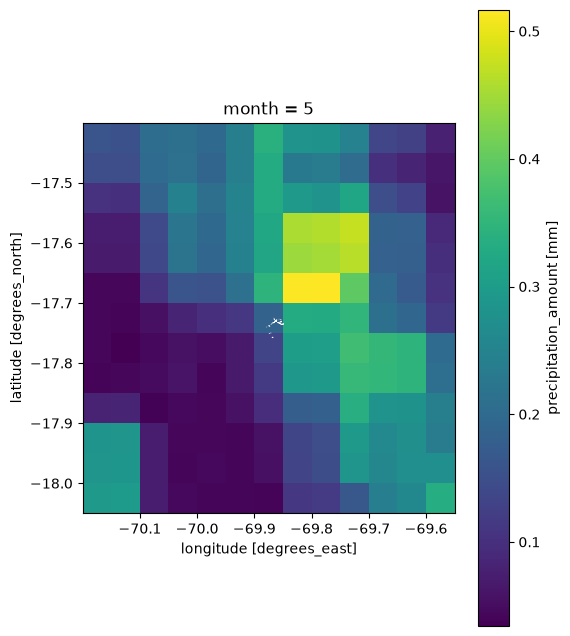

In [ ]:
# Visualización de la precipitación promedio del área de los bofedales de Caplina en junio 
fig, ax = plt.subplots(figsize=(6,8))
p_cap_serv.groupby('time.month').mean().sel(month=5).plot()
bof_caplina.plot(ax=ax, facecolor='none', edgecolor='white', linewidth=0.5)

## Cobertura de suelo
### 1. MapBiomas

### 2. MODIS/061/MCD12Q1

In [ ]:
# Primero se debe ingresar a GEE
# 1. Autenticación
ee.Authenticate(auth_mode='notebook')

# 2. Inicializar la sesión de Earth Engine
ee.Initialize(project='proyecto-sig-25112025')

True

In [ ]:
# Con los datos de límites de georecortes se generan regiones para la selección espacial de datos
r_antauta = ee.Geometry.Rectangle(box_antauta)
r_caplina = ee.Geometry.Rectangle(box_caplina)

In [19]:
def descargar(img, region, nombre, escala):
    """Descarga el recorte de una imagen de GEE como GeoTIFF y lo abre con rioxarray."""
    url = img.getDownloadURL({
        "region": region,
        "scale": escala,
        "crs": "EPSG:4326",
        "format": "GEO_TIFF",
    })
    r = requests.get(url, timeout=300)
    r.raise_for_status()
    with open(nombre, "wb") as f:
        f.write(r.content)
    print(nombre, f"{len(r.content) / 1e6:.1f} MB")
    return rio.open_rasterio(nombre).squeeze("band", drop=True)

In [ ]:
# La resolución temporal de MODIS es anual. El conjunto de imágenes .tiff se usan para crear un archivo .nc que contenga la información del rango temporal de interés
anios = range(2001, 2025)

# Listas para almacenar los DataArrays de cada año
lista_antauta = []
lista_caplina = []

# Se crean carpetas temporales para organizar los .tif. Luego se eliminan
os.makedirs("tifs_antauta", exist_ok=True)
os.makedirs("tifs_caplina", exist_ok=True)

# Asimismo, se crea una carpeta para guardar los datos .nc
os.makedirs("datos_brutos/datos_MODIS", exist_ok=True)

# Bucle para iterar año por año. PASO APOYADO DE IA
for anio in anios:
    print(f"Procesando año {anio}...")

    # Filtrar la colección de GEE para el año actual
    modis_img = (
        ee.ImageCollection("MODIS/061/MCD12Q1")
        .filterDate(f"{anio}-01-01", f"{anio}-12-31")
        .select("LC_Type1")
        .first()
    )

    # Definir la fecha asignada (1 de enero del año)
    fecha = pd.to_datetime(f"{anio}-01-01")

    # Nombres de archivos .tif
    nombre_ant = f"tifs_antauta/modis_antauta_{anio}.tif"
    nombre_cap = f"tifs_caplina/modis_caplina_{anio}.tif"

    # Descargar .tif y cargar como DataArray
    da_ant = descargar(modis_img, r_antauta, nombre_ant, 500)
    da_cap = descargar(modis_img, r_caplina, nombre_cap, 500)

    # Agregar la dimensión de tiempo con la fecha correspondiente
    da_ant = da_ant.expand_dims(time=[fecha])
    da_cap = da_cap.expand_dims(time=[fecha])

    # Guardar en las listas
    lista_antauta.append(da_ant)
    lista_caplina.append(da_cap)

# Se concatenan todas las imágenes anuales a lo largo de la dimensión 'time'
ds_antauta = xr.concat(lista_antauta, dim='time')
ds_caplina = xr.concat(lista_caplina, dim='time')

# Se asigna un nombre a la variable de cada dataset
ds_antauta.name = 'land_cover'
ds_caplina.name = 'land_cover'

# Finalmente, se exportan los archivos como .nc y se borran las carpetas temporales
ds_antauta.to_netcdf("datos_brutos/datos_MODIS/MODIS_antauta.nc")
ds_caplina.to_netcdf("datos_brutos/datos_MODIS/MODIS_caplina.nc")

shutil.rmtree("tifs_antauta")
shutil.rmtree("tifs_caplina")

Procesando año 2001...
tifs_antauta/modis_antauta_2001.tif 0.0 MB
tifs_caplina/modis_caplina_2001.tif 0.0 MB
Procesando año 2002...
tifs_antauta/modis_antauta_2002.tif 0.0 MB
tifs_caplina/modis_caplina_2002.tif 0.0 MB
Procesando año 2003...
tifs_antauta/modis_antauta_2003.tif 0.0 MB
tifs_caplina/modis_caplina_2003.tif 0.0 MB
Procesando año 2004...
tifs_antauta/modis_antauta_2004.tif 0.0 MB
tifs_caplina/modis_caplina_2004.tif 0.0 MB
Procesando año 2005...
tifs_antauta/modis_antauta_2005.tif 0.0 MB
tifs_caplina/modis_caplina_2005.tif 0.0 MB
Procesando año 2006...
tifs_antauta/modis_antauta_2006.tif 0.0 MB
tifs_caplina/modis_caplina_2006.tif 0.0 MB
Procesando año 2007...
tifs_antauta/modis_antauta_2007.tif 0.0 MB
tifs_caplina/modis_caplina_2007.tif 0.0 MB
Procesando año 2008...
tifs_antauta/modis_antauta_2008.tif 0.0 MB
tifs_caplina/modis_caplina_2008.tif 0.0 MB
Procesando año 2009...
tifs_antauta/modis_antauta_2009.tif 0.0 MB
tifs_caplina/modis_caplina_2009.tif 0.0 MB
Procesando año 2010

In [63]:
# Leer los archivos creados
m_ant = xr.open_dataset('/home/sebas/GitHub/geocomp_TF/datos_brutos/datos_MODIS/MODIS_antauta.nc')
m_cap = xr.open_dataset('/home/sebas/GitHub/geocomp_TF/datos_brutos/datos_MODIS/MODIS_caplina.nc')

# Asignar la variable 'land_cover'
modis_ant = m_ant['land_cover']
modis_cap = m_ant['land_cover']

6.0 Arbustales cerrados    0.0%
9.0 Sabanas                0.0%
10.0 Praderas              99.0%
11.0 Humedales permanentes   0.0%
13.0 Terrenos urbanos y edificados   0.1%
15.0 Nieve y hielo          0.0%
16.0 Suelo desierto         0.9%


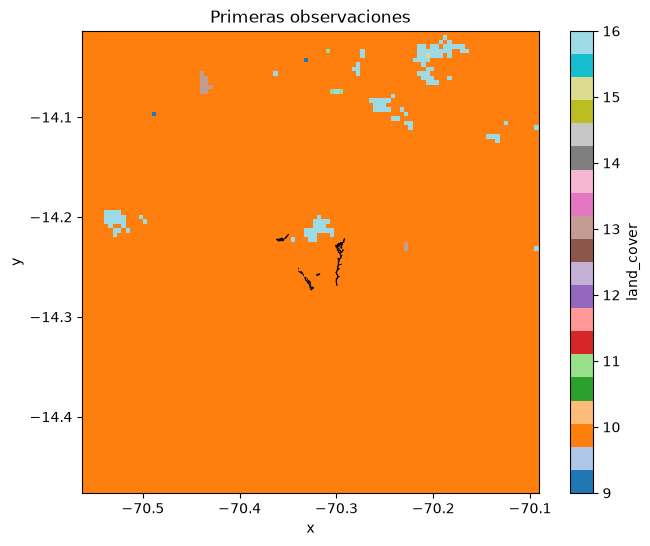

In [ ]:
# Se define la clasificación de clases de MODIS 
CLASES_MODIS = {
    1: "Bosques de hojas aciculares perennes",
    2: "Bosques perennifolios de hoja ancha",
    3: "Bosques de coníferas caducifolias",
    4: "Bosques caducifolios de hoja ancha",
    5: "Bosques mixtos",
    6: "Arbustales cerrados",
    7: "Arbustales abiertos",
    8: "Sabanas arboladas",
    9: "Sabanas",
    10: "Praderas",
    11: "Humedales permanentes",
    12: "Tierras de cultivo",
    13: "Terrenos urbanos y edificados",
    14: "Mosaicos de tierras de cultivo y vegetación natural",
    15: "Nieve y hielo",
    16: "Suelo desierto",
    17: "Cuerpos de agua",
}

# Se extraen los códigos únicos presentes en el mapa y se cuenta la frecuencia de cada clase
codigos, cuentas = np.unique(modis_ant.values, return_counts=True)
for cod,k in zip(codigos,cuentas):
    print(f"{cod:>3} {CLASES_MODIS.get(int(cod),'?'):<20} {100*k/cuentas.sum():5.1f}%")

# Se grafica el mapa de cobertura de suelo para un año específico
fig, ax = plt.subplots(figsize=(8, 6))  
modis_ant.sel(time='2001-01-01').plot(cmap="tab20") # El año se cambia para alternar entre diferentes datos dentro del .nc
bof_antauta.plot(ax=ax, facecolor='none', edgecolor='k', linewidth=0.5)

plt.title("Primeras observaciones")
plt.show() 